# Avaliação final dos modelos

## Objetivo
Comparar DummyClassifier, Logistic Regression e Random Forest no conjunto de teste reservado. Os pipelines foram ajustados no conjunto de treino no notebook 03; aqui apenas carregamos os artefatos, geramos previsões para o teste uma vez e calculamos as métricas.

## Métricas e interpretação
- **Accuracy:** fração total de previsões corretas; pode esconder a classe minoritária.
- **Precision:** entre os clientes previstos como `yes`, quantos realmente aderiram.
- **Recall:** entre os que aderiram, quantos o modelo encontrou.
- **F1:** média harmônica entre precision e recall.
- **Matriz de confusão:** TN, FP, FN e TP com linhas = valor real e colunas = previsto.
- **ROC-AUC:** capacidade de ordenar positivos acima de negativos em diferentes limiares.
- **Average Precision / curva Precision-Recall:** resume precision e recall em vários limiares; é especialmente informativa quando a classe positiva é rara.

As previsões de classe usam o limiar padrão de cada pipeline (0,5 para a classe positiva quando o estimador decide por probabilidade). Não ajustaremos limiar ou hiperparâmetros com o teste. Se um ajuste for necessário depois, a validação será feita dentro do treino por validação cruzada estratificada.

In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from preprocessing import load_dataset, prepare_features_target, split_data

MODELS_PATH = PROJECT_ROOT / "results" / "models"
FIGURES_PATH = PROJECT_ROOT / "results" / "figures"
TABLES_PATH = PROJECT_ROOT / "results" / "tables"
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
TABLES_PATH.mkdir(parents=True, exist_ok=True)

print(f"Raiz do projeto: {PROJECT_ROOT}")

Raiz do projeto: C:\Users\User\Documents\Codex\2026-11-09\files-pasted-by-the-user-projeto


## Recriar a divisão e carregar modelos

Usamos a mesma função, proporção e semente das etapas anteriores. O conjunto de teste contém 8.238 registros. Carregamos os artefatos já treinados; não chamamos `.fit()` aqui.

In [2]:
df = load_dataset()
X, y = prepare_features_target(df)
X_train, X_test, y_train, y_test = split_data(
    X, y, test_size=0.2, random_state=42
)

model_paths = {
    "DummyClassifier": MODELS_PATH / "dummy_pipeline.joblib",
    "Logistic Regression": MODELS_PATH / "logistic_regression_pipeline.joblib",
    "Random Forest": MODELS_PATH / "random_forest_pipeline.joblib",
}
models = {}
for model_name, model_path in model_paths.items():
    if not model_path.is_file():
        raise FileNotFoundError(f"Modelo não encontrado: {model_path}. Execute antes o notebook 03.")
    models[model_name] = joblib.load(model_path)

print(f"Tamanho do teste reservado para avaliação: {len(X_test):,}")
print(f"Modelos carregados: {list(models)}")

Tamanho do teste reservado para avaliação: 8,238
Modelos carregados: ['DummyClassifier', 'Logistic Regression', 'Random Forest']


## Calcular métricas no teste

Cada pipeline recebe o mesmo `X_test` para produzir uma classe e uma probabilidade de `yes`. Fazemos isso uma vez por modelo e calculamos todas as métricas a partir dessas previsões. `zero_division=0` deixa explícito que precision vale zero quando um modelo não prevê nenhum positivo.

A matriz segue a ordem `[no, yes]`: TN fica no canto superior esquerdo, FP no superior direito, FN no inferior esquerdo e TP no inferior direito.

In [3]:
positive_label = "yes"
y_test_binary = y_test.eq(positive_label).astype(int)
records = []
evaluation_details = {}

for model_name, pipeline in models.items():
    y_pred = pipeline.predict(X_test)
    class_labels = pipeline.named_steps["classifier"].classes_
    positive_index = list(class_labels).index(positive_label)
    y_score = pipeline.predict_proba(X_test)[:, positive_index]

    matrix = confusion_matrix(y_test, y_pred, labels=["no", "yes"])
    tn, fp, fn, tp = matrix.ravel()
    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
        "recall": recall_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
        "f1_score": f1_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
        "roc_auc": roc_auc_score(y_test_binary, y_score),
        "average_precision": average_precision_score(y_test_binary, y_score),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }
    records.append(metrics)
    evaluation_details[model_name] = {
        "y_pred": y_pred,
        "y_score": y_score,
        "confusion_matrix": matrix,
    }

comparison_table = pd.DataFrame(records)
metric_columns = ["accuracy", "precision", "recall", "f1_score", "roc_auc", "average_precision"]
display(comparison_table.style.format({column: "{:.4f}" for column in metric_columns}))

csv_path = TABLES_PATH / "model_comparison.csv"
comparison_table.to_csv(csv_path, index=False, encoding="utf-8")
print(f"Tabela salva em {csv_path.relative_to(PROJECT_ROOT)}")

,model,accuracy,precision,recall,f1_score,roc_auc,average_precision,tn,fp,fn,tp
0,DummyClassifier,0.8874,0.0000,0.0000,0.0000,0.5000,0.1126,7310,0,928,0
1,Logistic Regression,0.8350,0.3677,0.6455,0.4685,0.8009,0.4602,6280,1030,329,599
2,Random Forest,0.8772,0.4574,0.4860,0.4713,0.7866,0.3912,6775,535,477,451


Tabela salva em results\tables\model_comparison.csv


## Matrizes de confusão

As matrizes deixam visíveis os tipos de erro. **FP** são clientes previstos como interessados que não aderiram; **FN** são clientes que aderiram, mas não foram identificados. O custo de cada tipo de erro depende do objetivo da campanha.

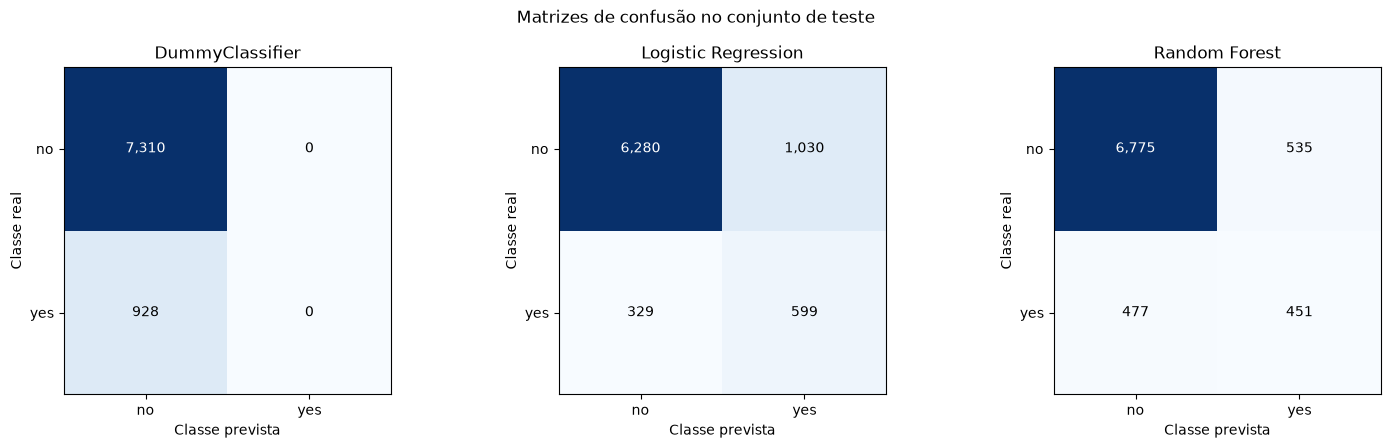

Figura salva em results\figures\model_confusion_matrices.png


In [4]:
fig, axes = plt.subplots(1, len(models), figsize=(15, 4.5))
for ax, (model_name, details) in zip(axes, evaluation_details.items()):
    matrix = details["confusion_matrix"]
    ax.imshow(matrix, cmap="Blues")
    ax.set_title(model_name)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.set_xticks([0, 1], labels=["no", "yes"])
    ax.set_yticks([0, 1], labels=["no", "yes"])
    threshold = matrix.max() / 2
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f"{matrix[row, col]:,}", ha="center", va="center",
                    color="white" if matrix[row, col] > threshold else "black")
fig.suptitle("Matrizes de confusão no conjunto de teste")
fig.tight_layout()
confusion_path = FIGURES_PATH / "model_confusion_matrices.png"
fig.savefig(confusion_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figura salva em {confusion_path.relative_to(PROJECT_ROOT)}")

## Curva ROC

Cada curva mostra a taxa de verdadeiros positivos contra a taxa de falsos positivos conforme o limiar varia. A diagonal representa uma ordenação sem poder discriminativo. O AUC resume a curva; valores maiores indicam melhor separação das classes na amostra de teste, mas não representam certeza sobre clientes individuais.

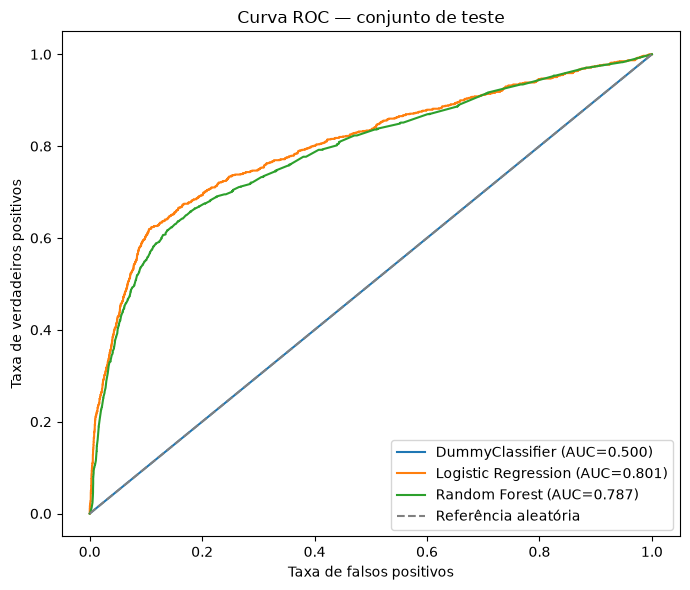

Figura salva em results\figures\model_roc_curves.png


In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
for model_name, details in evaluation_details.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test_binary, details["y_score"])
    auc_value = roc_auc_score(y_test_binary, details["y_score"])
    ax.plot(false_positive_rate, true_positive_rate, label=f"{model_name} (AUC={auc_value:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referência aleatória")
ax.set(title="Curva ROC — conjunto de teste", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
ax.legend(loc="lower right")
fig.tight_layout()
roc_path = FIGURES_PATH / "model_roc_curves.png"
fig.savefig(roc_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figura salva em {roc_path.relative_to(PROJECT_ROOT)}")

## Curva Precision-Recall

A curva mostra o compromisso entre precision e recall para diferentes limiares. A linha horizontal representa a prevalência de `yes` no teste e serve como referência simples. Average Precision resume a curva; ela não deve ser confundida com a precision em um único limiar.

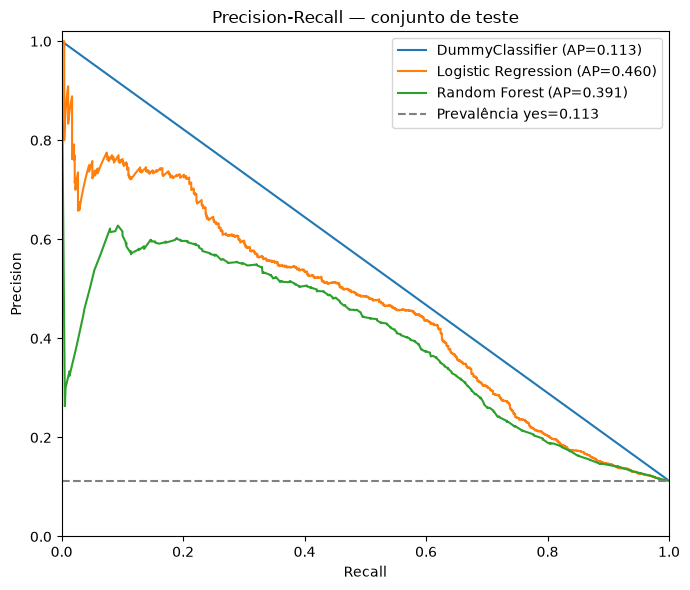

Figura salva em results\figures\model_precision_recall_curves.png


In [6]:
test_prevalence = y_test_binary.mean()
fig, ax = plt.subplots(figsize=(7, 6))
for model_name, details in evaluation_details.items():
    precisions, recalls, _ = precision_recall_curve(y_test_binary, details["y_score"])
    ap_value = average_precision_score(y_test_binary, details["y_score"])
    ax.plot(recalls, precisions, label=f"{model_name} (AP={ap_value:.3f})")
ax.axhline(test_prevalence, linestyle="--", color="gray", label=f"Prevalência yes={test_prevalence:.3f}")
ax.set(title="Precision-Recall — conjunto de teste", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="best")
fig.tight_layout()
pr_path = FIGURES_PATH / "model_precision_recall_curves.png"
fig.savefig(pr_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figura salva em {pr_path.relative_to(PROJECT_ROOT)}")

## Síntese

Use a tabela para comparar os três modelos em todas as métricas e as matrizes para ver os erros concretos. Accuracy alta, isoladamente, não escolhe um modelo adequado: em uma classe minoritária, recall, precision, F1 e Average Precision ajudam a revelar outros trade-offs. A escolha deve considerar o objetivo da campanha e o custo de FP versus FN.

Esta é a avaliação final planejada no conjunto de teste. Nenhum limiar ou hiperparâmetro foi ajustado a partir destes resultados. A análise de interpretação ficará no notebook 05.